In [4]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

In [5]:
# df = pd.read_csv("finalized_dataset.csv")
df = pd.read_csv("data/train_and_validate.csv")
df.head()

,uniProtkbId,proteinName,sequence,location
0,PAR3_HUMAN,Proteinase-activated receptor 3,MKALIFAAAGLLLLLPTFCQSGMENDTNNLAKPTLPIKTFRGAPPN...,Cell membrane
1,MICA3_HUMAN,[F-actin]-monooxygenase MICAL3,MEERKHETMNPAHVLFDRFVQATTCKGTLKAFQELCDHLELKPKDY...,Nucleus
2,FGFR3_HUMAN,Fibroblast growth factor receptor 3,MGAPACALALCVAVAIVAGASSESLGTEQRVVGRAAEVPGPEPGQQ...,Cell membrane
3,ZN384_HUMAN,Zinc finger protein 384,MEESHFNSNPYFWPSIPTVSGQIENTMFINKMKDQLLPEKGCGLAP...,Nucleus
4,ZTRF1_HUMAN,Zinc finger TRAF-type-containing protein 1,MSGAEEAGGGGPAAGPAGSVPAGVGVGVGAGPGAAAGQAAAAALGE...,Cytoplasm


In [6]:
df.describe()

,uniProtkbId,proteinName,sequence,location
count,12136,12136,12136,12136
unique,9603,9603,9579,3
top,P53_HUMAN,Cellular tumor antigen p53,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,Nucleus
freq,12,12,12,4690


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12136 entries, 0 to 12135
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   uniProtkbId  12136 non-null  object
 1   proteinName  12136 non-null  object
 2   sequence     12136 non-null  object
 3   location     12136 non-null  object
dtypes: object(4)
memory usage: 379.4+ KB


In [8]:
# DROP rows where sequence is missing
df = df.dropna(subset=['sequence'])

# Check the columns
print(df.columns)

# Assume the important columns are 'sequence' and 'location' (change if different)
sequences = df['sequence'].values
# labels = df['subcellularLocationSingle'].values
labels = df['location'].values


Index(['uniProtkbId', 'proteinName', 'sequence', 'location'], dtype='object')


In [9]:
# Encode Labels
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

(array([3516.,    0.,    0.,    0.,    0., 3930.,    0.,    0.,    0.,
        4690.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

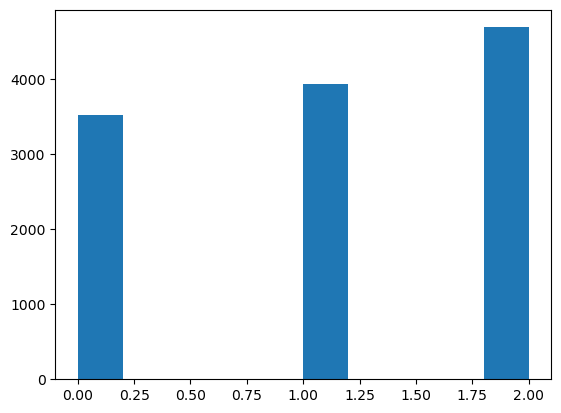

In [7]:
plt.hist(labels_encoded)

In [13]:
# Amino acid to index
amino_acids = "ACDEFGHIKLMNPQRSTVWY"  # Standard 20 amino acids
aa_to_idx = {aa: idx+1 for idx, aa in enumerate(amino_acids)}  # start from 1 (0 for padding)

# Custom Dataset
class ProteinDataset(Dataset):
    def __init__(self, sequences, labels, aa_to_idx):
        self.sequences = sequences
        self.labels = labels
        self.aa_to_idx = aa_to_idx

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq = self.sequences[idx]
        label = self.labels[idx]
        encoded_seq = [self.aa_to_idx.get(aa, 0) for aa in seq]  # unknowns get 0
        return torch.tensor(encoded_seq, dtype=torch.long), torch.tensor(label, dtype=torch.long)
    


# Collate function for padding
def collate_fn(batch):
    sequences, labels = zip(*batch)
    sequences_padded = pad_sequence(sequences, batch_first=True, padding_value=0)
    labels = torch.stack(labels)
    return sequences_padded, labels

In [ ]:

# Dataset and Dataloaders
dataset = ProteinDataset(sequences, labels_encoded, aa_to_idx)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Hyperparameters
vocab_size = len(aa_to_idx) + 1  # plus 1 for padding
num_classes = len(label_encoder.classes_)

# Tunable Hyperparameters
embed_dim = 64
batch_size = 32
drop_out_rate = 0.5
learning_rate = 0.0001
n_epochs = 30


train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# Define Model
class ProteinClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes):
        super(ProteinClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.conv1 = nn.Conv1d(embed_dim, 128, kernel_size=5, padding=2)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.dropout = nn.Dropout(drop_out_rate)   
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.embedding(x)  # (batch, seq_len, embed_dim)
        x = x.permute(0, 2, 1)  # (batch, embed_dim, seq_len)
        x = torch.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        x = self.dropout(x) 
        x = self.fc(x)
        return x

# Deeper model
class DeepProteinClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes):
        super(DeepProteinClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        self.conv_block = nn.Sequential(
            nn.Conv1d(embed_dim, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Conv1d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AdaptiveMaxPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Dropout(drop_out_rate),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(drop_out_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.embedding(x)          # (batch, seq_len, embed_dim)
        x = x.permute(0, 2, 1)         # (batch, embed_dim, seq_len)
        x = self.conv_block(x).squeeze(-1)
        return self.classifier(x)

class CNNTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes, num_heads=4, transformer_dim=128, ff_dim=256, num_layers=1):
        super(CNNTransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # CNN Layer (shallow)
        self.conv1 = nn.Conv1d(embed_dim, 128, kernel_size=5, padding=2)
        self.pool = nn.AdaptiveMaxPool1d(1)

        # Transformer Encoder Layer
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                                   dim_feedforward=ff_dim, dropout=0.1, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Fully connected classifier
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(128 + embed_dim, num_classes)  # combining CNN and transformer features

    def forward(self, x):
        embedded = self.embedding(x)  # (B, L, E)

        # CNN branch
        cnn_input = embedded.permute(0, 2, 1)  # (B, E, L)
        cnn_features = F.relu(self.conv1(cnn_input))  # (B, 128, L)
        cnn_features = self.pool(cnn_features).squeeze(-1)  # (B, 128)

        # Transformer branch
        transformer_features = self.transformer_encoder(embedded)  # (B, L, E)
        transformer_features = transformer_features.mean(dim=1)  # mean-pool over sequence (B, E)

        # Concatenate both branches
        combined = torch.cat([cnn_features, transformer_features], dim=1)  # (B, 128 + E)

        # Classification head
        output = self.dropout(combined)
        output = self.fc(output)
        return output

model = ProteinClassifier(vocab_size, embed_dim, num_classes)
# model = DeepProteinClassifier(vocab_size, embed_dim, num_classes)
# model = CNNTransformerClassifier(vocab_size=vocab_size, embed_dim=embed_dim, num_classes=num_classes)


# Training Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

Epoch 1/50 | Train Loss: 1.2409 | Val Loss: 1.0399 | Train Acc: 0.3599 | Val Acc: 0.5103
Epoch 2/50 | Train Loss: 1.1281 | Val Loss: 1.0109 | Train Acc: 0.4048 | Val Acc: 0.4946
Epoch 3/50 | Train Loss: 1.0679 | Val Loss: 0.9855 | Train Acc: 0.4398 | Val Acc: 0.5362
Epoch 4/50 | Train Loss: 1.0365 | Val Loss: 0.9626 | Train Acc: 0.4568 | Val Acc: 0.5667
Epoch 5/50 | Train Loss: 1.0130 | Val Loss: 0.9449 | Train Acc: 0.4771 | Val Acc: 0.5762
Epoch 6/50 | Train Loss: 0.9824 | Val Loss: 0.9293 | Train Acc: 0.5062 | Val Acc: 0.5548
Epoch 7/50 | Train Loss: 0.9714 | Val Loss: 0.9135 | Train Acc: 0.5100 | Val Acc: 0.5721
Epoch 8/50 | Train Loss: 0.9450 | Val Loss: 0.8995 | Train Acc: 0.5247 | Val Acc: 0.5848
Epoch 9/50 | Train Loss: 0.9331 | Val Loss: 0.8884 | Train Acc: 0.5379 | Val Acc: 0.5951
Epoch 10/50 | Train Loss: 0.9246 | Val Loss: 0.8758 | Train Acc: 0.5381 | Val Acc: 0.5988
Epoch 11/50 | Train Loss: 0.9087 | Val Loss: 0.8636 | Train Acc: 0.5522 | Val Acc: 0.5997
Epoch 12/50 | Train

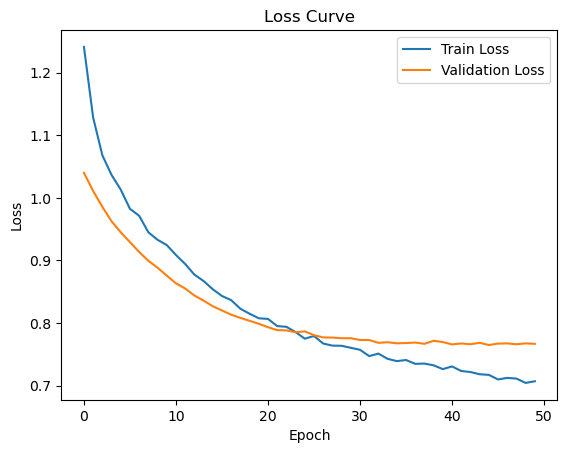

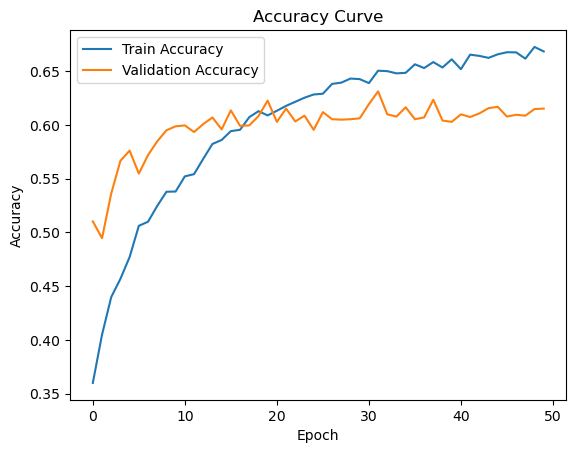

In [ ]:


# Training Loop
# Initialize lists
num_epochs = n_epochs
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        _, predicted = outputs.max(1)
        correct += predicted.eq(targets).sum().item()
        total += targets.size(0)

    train_losses.append(running_loss / len(train_loader))
    train_accuracies.append(correct / total)

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item()

            # Validation Accuracy
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(targets).sum().item()
            val_total += targets.size(0)

    val_losses.append(val_loss / len(val_loader))
    val_accuracies.append(val_correct / val_total)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Train Acc: {train_accuracies[-1]:.4f} | Val Acc: {val_accuracies[-1]:.4f}")


# Plot Loss
plt.figure()
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')
plt.savefig('loss_curve.png')
print('Saved loss curve to loss_curve.png')

# Plot Accuracy
plt.figure()
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy Curve')
plt.savefig('accuracy_curve.png')
print('Saved accuracy curve to accuracy_curve.png')


# Save the model
torch.save(model.state_dict(), 'protein_classifier.pth')

# To load it back later:
# model.load_state_dict(torch.load('protein_classifier.pth'))
# model.eval()


### Evaluating Test/Blind Data

In [10]:
df = pd.read_csv("data/test.csv")

sequences = df['sequence'].values
labels = df['location'].values
labels_encoded = label_encoder.fit_transform(labels)
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 834 entries, 0 to 833
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   uniProtkbId  834 non-null    object
 1   proteinName  834 non-null    object
 2   sequence     834 non-null    object
 3   location     834 non-null    object
dtypes: object(4)
memory usage: 26.2+ KB


In [17]:
# To load it back later:
model.load_state_dict(torch.load('protein_classifier.pth'))
model.eval()

ProteinClassifier(
  (embedding): Embedding(21, 64, padding_idx=0)
  (conv1): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (pool): AdaptiveMaxPool1d(output_size=1)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)

In [ ]:
from sklearn.metrics import accuracy_score

# def evaluate(model, dataloader, device):
#     model.eval()  # Set model to evaluation mode
#     all_preds = []
#     all_labels = []
    
#     with torch.no_grad():  # Turn off gradients for evaluation
#         for inputs, labels in dataloader:
#             inputs = inputs.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1).cpu().numpy()
#             all_preds.extend(preds)
#             all_labels.extend(labels.numpy())

#     acc = accuracy_score(all_labels, all_preds)
#     return acc

# from sklearn.metrics import accuracy_score
# import torch.nn as nn

def evaluate(model, dataloader, device):
    model.eval()  # Set model to evaluation mode
    all_preds = []
    all_labels = []
    total_loss = 0.0

    criterion = nn.CrossEntropyLoss()  # Define loss function

    with torch.no_grad():  # Turn off gradients for evaluation
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    avg_loss = total_loss / len(dataloader)  # Average loss per batch
    return acc, avg_loss



In [18]:

test_dataset = ProteinDataset(sequences, labels_encoded, aa_to_idx)
test_loader = DataLoader(test_dataset, batch_size=16,shuffle=True, collate_fn=collate_fn)


# Evaluate
test_acc, avg_loss= evaluate(model, test_loader, device)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {avg_loss:.4f}")


Test Accuracy: 0.7386
Test Loss: 0.6124
